In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels=  [ 
    "cr_Zmumu_noLJ",
    "cr_Zmumu_noLJ_prompt",
    "cr_Zmumu_noLJ_displaced",
           ]

samples_separate = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
samples = ["bgs", "data", "TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [13]:
binning =2j
def plot_ratio_disp(histogram_name, binning=1j):
    plt.figure(figsize=(15, 12))
    for i, s in enumerate(samples[:2]):
        # ax =  axs[i]
        num_hist = sum_hist["cr_Zmumu_noLJ_displaced"][s][histogram_name]["cr_Zmumu_noLJ_displaced", ::binning]
        den_hist = (sum_hist["cr_Zmumu_noLJ_displaced"][s][histogram_name]["cr_Zmumu_noLJ_displaced", ::binning]
                   + sum_hist["cr_Zmumu_noLJ_prompt"][s][histogram_name]["cr_Zmumu_noLJ_prompt", ::binning])
        try:
            effi, err = utilities.get_eff_hist(num_hist, den_hist)
            utilities.plot(effi, yerr=err,label = s, skip_label=True)
            print(effi.values())
        except:
            print(f"using gaussian ratio for {s}")
            effi, err= utilities._gaussian_ratio(num_hist, den_hist)
            utilities.plot(effi,yerr=err, label = s, skip_label=True)
            
# plt.ylim(0, 10)
    plt.legend()

    # plt.yscale("log")
    plt.ylim(0, 0.05)
    plt.show()

[3.14109659e-03 3.04808433e-03 2.97294720e-03 3.19023231e-03
 4.31287580e-03 4.13215681e-03 9.42798447e-03 1.20812514e-02
 5.44397952e-03 9.31997294e-03 1.10645410e-05 2.07506960e-02
 0.00000000e+00 2.90894334e-05 0.00000000e+00 7.36221260e-05]
[0.00428964 0.00436422 0.00483478 0.00527481 0.00454492 0.00647523
 0.00482218 0.00705882 0.00408163 0.00699301 0.         0.
 0.         0.01960784 0.         0.        ]


/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()


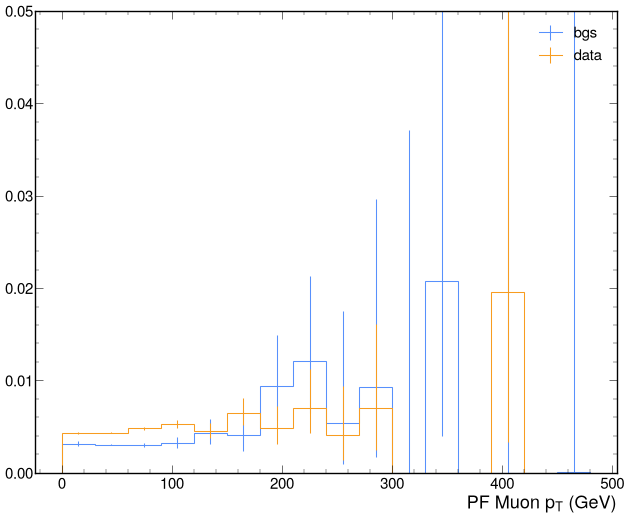

In [14]:

histogram_name = "muon_pt"
plot_ratio_disp (histogram_name, binning=6j)

/home/cms-jovyan/SIDM/sidm/tools/utilities.py:190: RuntimeWarning: invalid value encountered in divide
  eff_values = num_vals/denom_vals
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:196: RuntimeWarning: invalid value encountered in divide
  denom_counts = denom_vals**2 / denom_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:190: RuntimeWarning: invalid value encountered in divide
  eff_values = num_vals/denom_vals
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:196: RuntimeWarning: invalid value encountered in divide
  denom_counts = denom_vals**2 / denom_hist.variances()


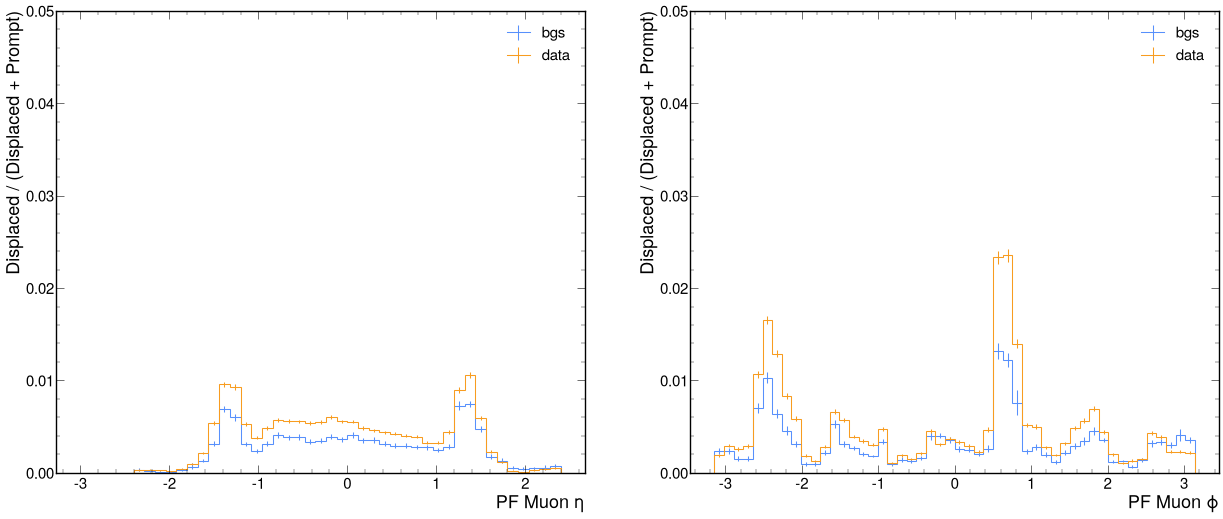

In [8]:
fig, axs = plt.subplots(1, 2, figsize = (30, 12))
# ratio = 6.616/62.061775847
for p in samples[:2]:
    histogram  = (sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :] + sum_hist["cr_Zmumu_noLJ_prompt"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_prompt", :, :])
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]

    eta = functions.plot_1d (histogram, "muons_eta" )
    phi = functions.plot_1d (histogram, "muons_phi" )
    disp_eta = functions.plot_1d (histogram_disp, "muons_eta" )
    disp_phi = functions.plot_1d (histogram_disp, "muons_phi" )

    ratio, err = utilities.get_eff_hist(disp_eta, eta)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[0])

    ratio, err = utilities.get_eff_hist(disp_phi, phi)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[1])


plt.legend()

axs[0].set_ylabel("Displaced / (Displaced + Prompt)")

axs[1].set_ylabel("Displaced / (Displaced + Prompt)")

axs [0].set_ylim(0, 0.05)
axs [1].set_ylim(0, 0.05)

axs[0].legend()
axs[0].axhline(y=1, linestyle="--", linewidth=2, color="k")
axs[1].axhline(y=1, linestyle="--", linewidth=2,  color="k")
axs[1].legend()
plt.show()